In [1]:
import pandas as pd
import numpy as np

# Create reproducible synthetic data
np.random.seed(42)

# Generate 2,000 dates for each of 2 products
dates = pd.date_range(start="2024-01-01", periods=2000, freq="D")

data = []

for date in dates:
    post_period = int(date >= pd.Timestamp("2025-05-15"))

    # Treatment product: price increases after intervention
    treatment_price = 500 if post_period == 0 else 540
    treatment_units = max(
        1, int(np.random.normal(25 - 2 * post_period, 3))
    )

    data.append([
        date, "Earphones", "Audio", treatment_price,
        treatment_units, post_period, 1, 0, post_period,
        treatment_price * treatment_units
    ])

    # Control product: price remains unchanged
    control_price = 200
    control_units = max(1, int(np.random.normal(40, 4)))

    data.append([
        date, "USB Cable", "Cables", control_price,
        control_units, 0, 0, 1, post_period,
        control_price * control_units
    ])

# Create DataFrame
columns = [
    "Date", "Product", "Category", "Price", "Units_Sold",
    "Price_Change", "Treatment_Group", "Control_Group",
    "Post_Period", "Revenue"
]

df = pd.DataFrame(data, columns=columns)

# Display results
print("Dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset created successfully!
Dataset shape: (4000, 10)


,Date,Product,Category,Price,Units_Sold,Price_Change,Treatment_Group,Control_Group,Post_Period,Revenue
0,2024-01-01,Earphones,Audio,500,26,0,1,0,0,13000
1,2024-01-01,USB Cable,Cables,200,39,0,0,1,0,7800
2,2024-01-02,Earphones,Audio,500,26,0,1,0,0,13000
3,2024-01-02,USB Cable,Cables,200,46,0,0,1,0,9200
4,2024-01-03,Earphones,Audio,500,24,0,1,0,0,12000


In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
df.info()

Missing Values:
Date               0
Product            0
Category           0
Price              0
Units_Sold         0
Price_Change       0
Treatment_Group    0
Control_Group      0
Post_Period        0
Revenue            0
dtype: int64

Duplicate Rows:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             4000 non-null   datetime64[ns]
 1   Product          4000 non-null   object        
 2   Category         4000 non-null   object        
 3   Price            4000 non-null   int64         
 4   Units_Sold       4000 non-null   int64         
 5   Price_Change     4000 non-null   int64         
 6   Treatment_Group  4000 non-null   int64         
 7   Control_Group    4000 non-null   int64         
 8   Post_Period      4000 non-null   int64         
 9   Revenue          4000 non

In [3]:
# Count treatment and control group records

print("Treatment Group:")
print(df["Treatment_Group"].value_counts())

print("\nControl Group:")
print(df["Control_Group"].value_counts())

print("\nAverage Units Sold by Product:")
print(df.groupby("Product")["Units_Sold"].mean())

print("\nAverage Revenue by Product:")
print(df.groupby("Product")["Revenue"].mean())

Treatment Group:
Treatment_Group
1    2000
0    2000
Name: count, dtype: int64

Control Group:
Control_Group
0    2000
1    2000
Name: count, dtype: int64

Average Units Sold by Product:
Product
Earphones    23.0275
USB Cable    39.6035
Name: Units_Sold, dtype: float64

Average Revenue by Product:
Product
Earphones    12189.95
USB Cable     7920.70
Name: Revenue, dtype: float64


In [4]:
# Compare average units sold before and after intervention

sales_comparison = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Units Sold Before and After Intervention:")
print(sales_comparison)

Average Units Sold Before and After Intervention:
Post_Period      0          1
Product                      
Earphones    24.49  22.540000
USB Cable    39.64  39.591333


In [5]:
# Calculate average sales before and after intervention

comparison = df.groupby(
    ["Treatment_Group", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Units Sold:")
print(comparison)

# Calculate Difference-in-Differences

treatment_change = comparison.loc[1, 1] - comparison.loc[1, 0]

control_change = comparison.loc[0, 1] - comparison.loc[0, 0]

did_effect = treatment_change - control_change

print("\nTreatment Group Change:", round(treatment_change, 2))
print("Control Group Change:", round(control_change, 2))
print("Difference-in-Differences Effect:", round(did_effect, 2))

Average Units Sold:
Post_Period          0          1
Treatment_Group                  
0                39.64  39.591333
1                24.49  22.540000

Treatment Group Change: -1.95
Control Group Change: -0.05
Difference-in-Differences Effect: -1.9


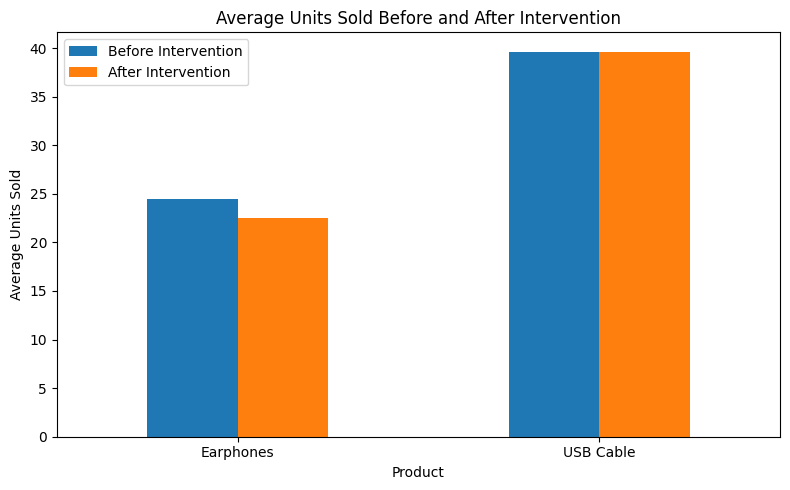

In [6]:
import matplotlib.pyplot as plt

sales_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Units Sold Before and After Intervention")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.legend(["Before Intervention", "After Intervention"])
plt.tight_layout()
plt.show()

In [7]:
# Save the dataset as a CSV file

df.to_csv("Pricing_Dataset_4000_Rows.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [8]:
from google.colab import files

files.download("Pricing_Dataset_4000_Rows.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import pandas as pd

df = pd.read_csv("Pricing_Dataset_4000_Rows.csv")

print(df.head())

         Date    Product Category  Price  Units_Sold  Price_Change  \
0  2024-01-01  Earphones    Audio    500          26             0   
1  2024-01-01  USB Cable   Cables    200          39             0   
2  2024-01-02  Earphones    Audio    500          26             0   
3  2024-01-02  USB Cable   Cables    200          46             0   
4  2024-01-03  Earphones    Audio    500          24             0   

   Treatment_Group  Control_Group  Post_Period  Revenue  
0                1              0            0    13000  
1                0              1            0     7800  
2                1              0            0    13000  
3                0              1            0     9200  
4                1              0            0    12000  


In [10]:
print(df.shape)
print(df.columns)

(4000, 10)
Index(['Date', 'Product', 'Category', 'Price', 'Units_Sold', 'Price_Change',
       'Treatment_Group', 'Control_Group', 'Post_Period', 'Revenue'],
      dtype='object')


In [11]:

import pandas as pd

# Convert Date column into date format
df["Date"] = pd.to_datetime(df["Date"])

# Compare sales and revenue before and after the intervention
analysis = df.groupby(
    ["Product", "Post_Period"]
).agg(
    Average_Units=("Units_Sold", "mean"),
    Total_Units=("Units_Sold", "sum"),
    Average_Revenue=("Revenue", "mean"),
    Total_Revenue=("Revenue", "sum")
).reset_index()

print(analysis)


     Product  Post_Period  Average_Units  Total_Units  Average_Revenue  \
0  Earphones            0      24.490000        12245     12245.000000   
1  Earphones            1      22.540000        33810     12171.600000   
2  USB Cable            0      39.640000        19820      7928.000000   
3  USB Cable            1      39.591333        59387      7918.266667   

   Total_Revenue  
0        6122500  
1       18257400  
2        3964000  
3       11877400  


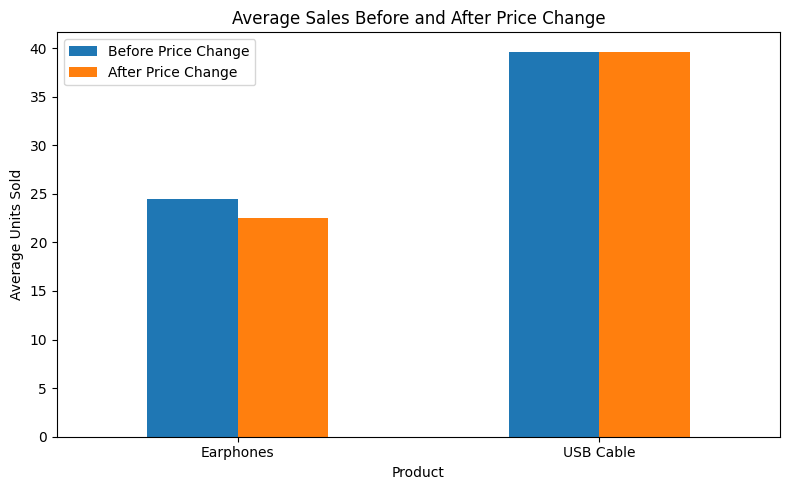

In [12]:
import matplotlib.pyplot as plt

sales = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().unstack()

sales.plot(kind="bar", figsize=(8, 5))

plt.title("Average Sales Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

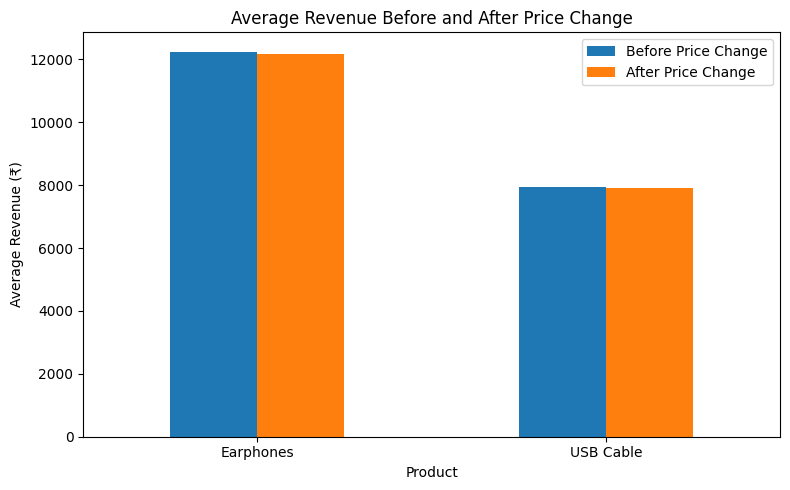

In [13]:
revenue = df.groupby(
    ["Product", "Post_Period"]
)["Revenue"].mean().unstack()

revenue.plot(kind="bar", figsize=(8, 5))

plt.title("Average Revenue Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Revenue (₹)")
plt.xticks(rotation=0)
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

In [14]:
# Calculate average sales for treatment and control groups

did_data = df.groupby(
    ["Treatment_Group", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Sales Before and After Price Change:")
print(did_data)

Average Sales Before and After Price Change:
Post_Period          0          1
Treatment_Group                  
0                39.64  39.591333
1                24.49  22.540000


In [15]:
# Treatment group sales change
treatment_change = did_data.loc[1, 1] - did_data.loc[1, 0]

# Control group sales change
control_change = did_data.loc[0, 1] - did_data.loc[0, 0]

# Difference-in-Differences
did_effect = treatment_change - control_change

print("Treatment Group Change:", treatment_change)
print("Control Group Change:", control_change)
print("DiD Effect:", did_effect)

Treatment Group Change: -1.9499999999999993
Control Group Change: -0.0486666666666693
DiD Effect: -1.90133333333333


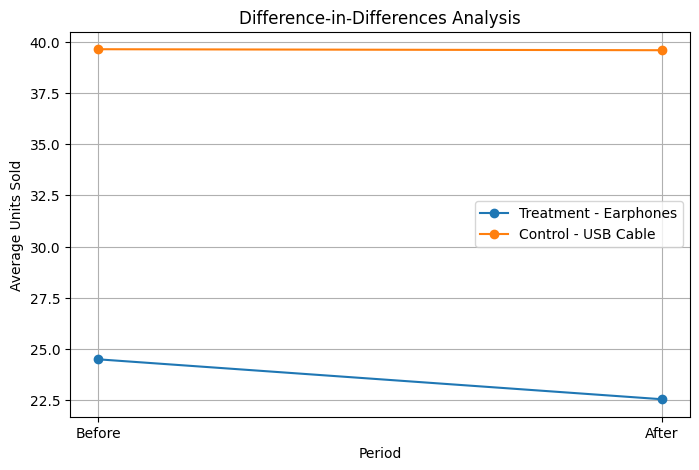

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    ["Before", "After"],
    [did_data.loc[1, 0], did_data.loc[1, 1]],
    marker="o",
    label="Treatment - Earphones"
)

plt.plot(
    ["Before", "After"],
    [did_data.loc[0, 0], did_data.loc[0, 1]],
    marker="o",
    label="Control - USB Cable"
)

plt.title("Difference-in-Differences Analysis")
plt.xlabel("Period")
plt.ylabel("Average Units Sold")
plt.legend()
plt.grid(True)
plt.show()

 Difference-in-Differences Analysis

The Difference-in-Differences method was used to estimate the effect of a price change on product sales. Earphones were selected as the treatment group, and USB Cable was selected as the control group.

The treatment group showed a decrease of 1.95 units, while the control group showed a change of approximately −0.05 units. The estimated DiD effect was −1.90 units.

This suggests that the price increase was associated with a relative decrease in Earphones sales in the synthetic dataset.

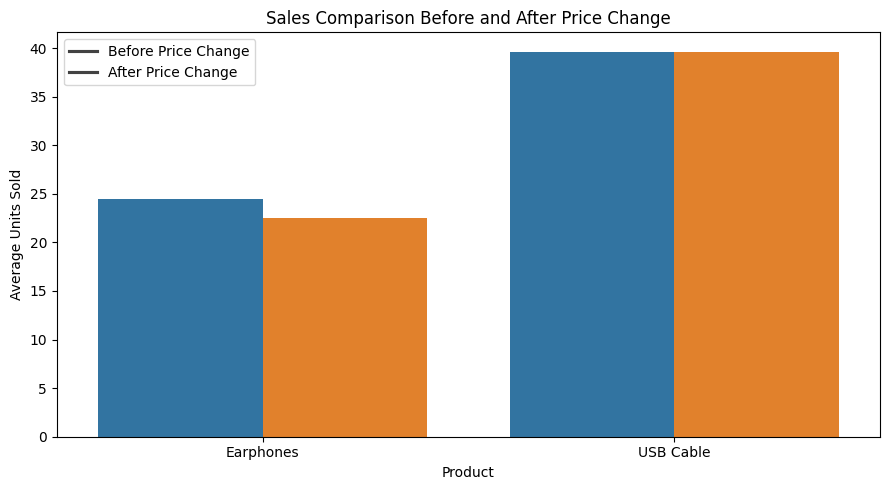

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average units sold before and after price change
sales_comparison = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sales_comparison,
    x="Product",
    y="Units_Sold",
    hue="Post_Period"
)

plt.title("Sales Comparison Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

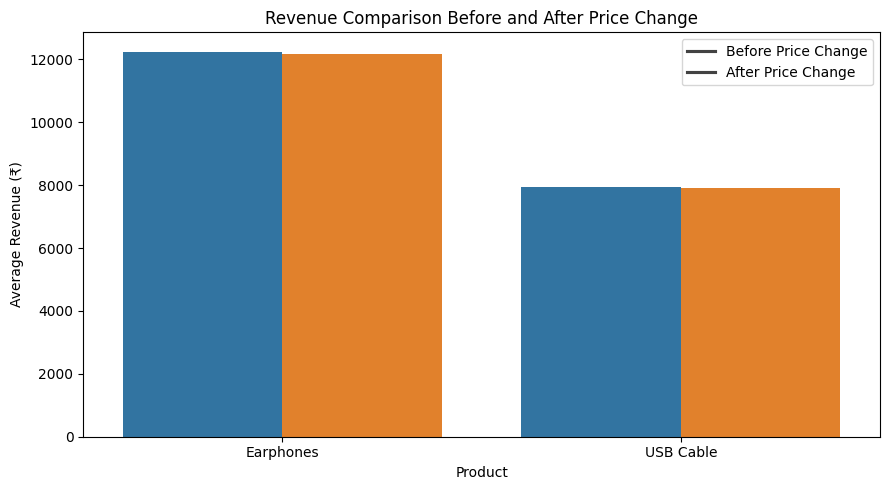

In [18]:
# Calculate average revenue before and after price change
revenue_comparison = df.groupby(
    ["Product", "Post_Period"]
)["Revenue"].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=revenue_comparison,
    x="Product",
    y="Revenue",
    hue="Post_Period"
)

plt.title("Revenue Comparison Before and After Price Change")
plt.xlabel("Product")
plt.ylabel("Average Revenue (₹)")
plt.legend(["Before Price Change", "After Price Change"])
plt.tight_layout()
plt.show()

##  Sales and Revenue Comparison – Findings

1. The sales comparison shows that average Earphones sales decreased after the price change.
2. USB Cable sales remained almost stable during both periods.
3. The revenue comparison shows a slight decrease in average revenue after the price change.
4. The Difference-in-Differences result is approximately -1.90 units.

### Conclusion
In this synthetic dataset, the price increase is associated with a decrease in Earphones sales compared with the control product. These results are illustrative and do not represent real-world business evidence.

In [19]:
# Day 6: Data Visualization and Interpretation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check the dataset
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.head()

Dataset Shape: (4000, 10)

Column Names:
['Date', 'Product', 'Category', 'Price', 'Units_Sold', 'Price_Change', 'Treatment_Group', 'Control_Group', 'Post_Period', 'Revenue']


,Date,Product,Category,Price,Units_Sold,Price_Change,Treatment_Group,Control_Group,Post_Period,Revenue
0,2024-01-01,Earphones,Audio,500,26,0,1,0,0,13000
1,2024-01-01,USB Cable,Cables,200,39,0,0,1,0,7800
2,2024-01-02,Earphones,Audio,500,26,0,1,0,0,13000
3,2024-01-02,USB Cable,Cables,200,46,0,0,1,0,9200
4,2024-01-03,Earphones,Audio,500,24,0,1,0,0,12000


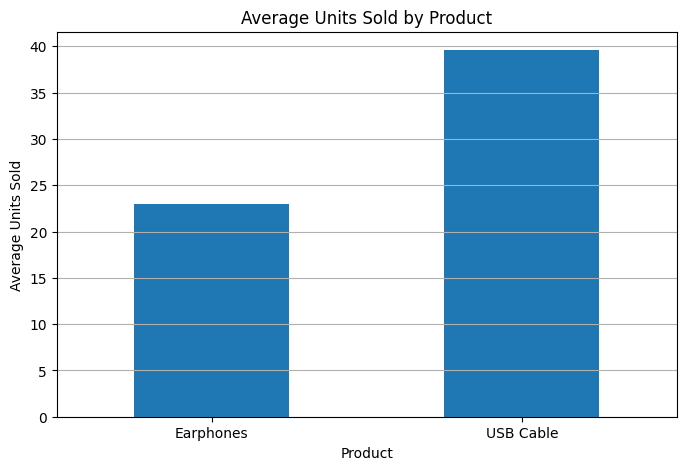

In [20]:
# Product-wise Average Sales

product_sales = df.groupby("Product")["Units_Sold"].mean()

plt.figure(figsize=(8, 5))
product_sales.plot(kind="bar")

plt.title("Average Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

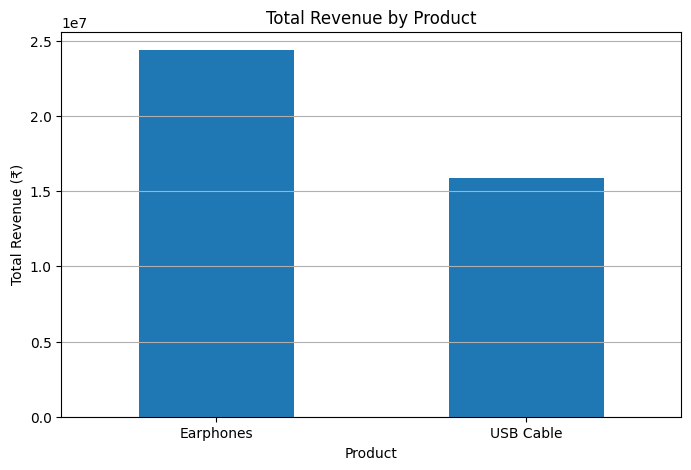

In [21]:
# Product-wise Revenue Comparison

product_revenue = df.groupby("Product")["Revenue"].sum()

plt.figure(figsize=(8, 5))
product_revenue.plot(kind="bar")

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

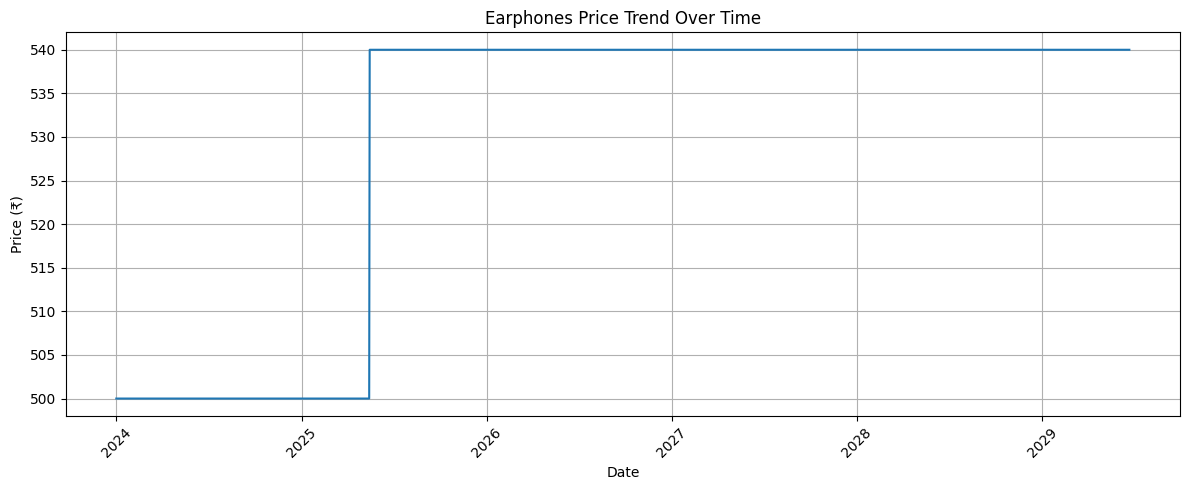

In [22]:
# Price Trend Over Time

earphones = df[df["Product"] == "Earphones"].copy()

daily_price = earphones.groupby("Date")["Price"].mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_price.index, daily_price.values)

plt.title("Earphones Price Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
print("Dataset shape:", df.shape)

print("\nAvailable products:")
print(df["Product"].unique())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nAverage daily sales:")
print(df.groupby("Product")["Units_Sold"].mean())

Dataset shape: (4000, 10)

Available products:
['Earphones' 'USB Cable']

Date range:
2024-01-01 00:00:00 to 2029-06-22 00:00:00

Average daily sales:
Product
Earphones    23.0275
USB Cable    39.6035
Name: Units_Sold, dtype: float64


In [24]:
# Check treatment and control groups

print("Treatment group:")
print(df[df["Treatment_Group"] == 1]["Product"].unique())

print("\nControl group:")
print(df[df["Control_Group"] == 1]["Product"].unique())

print("\nAverage daily sales by product:")
print(df.groupby("Product")["Units_Sold"].mean())

Treatment group:
['Earphones']

Control group:
['USB Cable']

Average daily sales by product:
Product
Earphones    23.0275
USB Cable    39.6035
Name: Units_Sold, dtype: float64


In [25]:
import numpy as np

np.random.seed(42)

donor_products = {
    "Power Bank": 30,
    "Bluetooth Speaker": 28,
    "Phone Case": 35,
    "Keyboard": 32
}

donor_data = []

for product, average_sales in donor_products.items():
    for date in sorted(df["Date"].unique()):
        units = max(1, int(np.random.normal(average_sales, 3)))

        donor_data.append({
            "Date": date,
            "Product": product,
            "Units_Sold": units
        })

donor_df = pd.DataFrame(donor_data)

print("Donor products created:")
print(donor_df["Product"].unique())

print("\nDonor dataset shape:", donor_df.shape)

Donor products created:
['Power Bank' 'Bluetooth Speaker' 'Phone Case' 'Keyboard']

Donor dataset shape: (8000, 3)


In [26]:
# Prepare pre-intervention data
intervention_date = pd.Timestamp("2025-05-15")

treatment = df[df["Product"] == "Earphones"].copy()
treatment = treatment.sort_values("Date")

donors = donor_df.copy()

# Calculate average sales before intervention
pre_treatment = treatment[
    treatment["Date"] < intervention_date
]

pre_donors = donors[
    donors["Date"] < intervention_date
]

donor_averages = pre_donors.groupby("Product")[
    "Units_Sold"
].mean()

print("Average donor sales before intervention:")
print(donor_averages)

# Calculate weights
weights = donor_averages / donor_averages.sum()

print("\nSynthetic Control Weights:")
print(weights)

# Calculate weighted synthetic sales for each date
donor_pivot = donors.pivot(
    index="Date",
    columns="Product",
    values="Units_Sold"
)

synthetic_sales = donor_pivot.dot(weights)

print("\nSynthetic sales calculated successfully!")
print(synthetic_sales.head())

Average donor sales before intervention:
Product
Bluetooth Speaker    27.498
Keyboard             31.434
Phone Case           34.202
Power Bank           29.522
Name: Units_Sold, dtype: float64

Synthetic Control Weights:
Product
Bluetooth Speaker    0.224188
Keyboard             0.256278
Phone Case           0.278845
Power Bank           0.240689
Name: Units_Sold, dtype: float64

Synthetic sales calculated successfully!
Date
2024-01-01    29.164884
2024-01-02    30.202126
2024-01-03    30.257696
2024-01-04    31.963263
2024-01-05    28.222085
dtype: float64


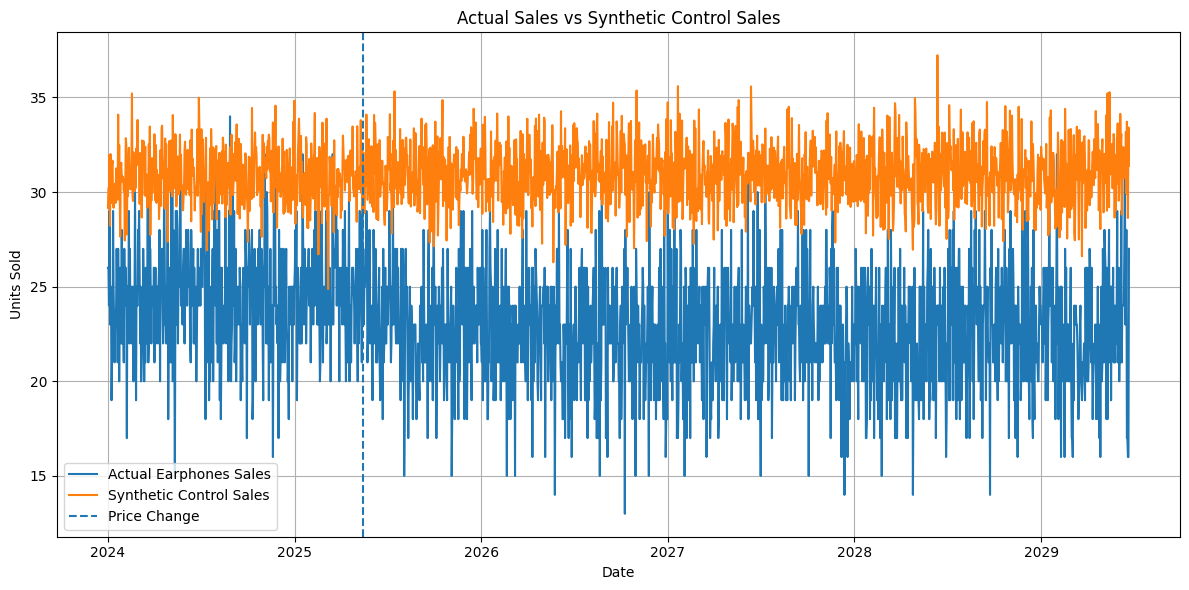

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Actual treatment group sales
actual_sales = df[df["Product"] == "Earphones"].groupby("Date")["Units_Sold"].mean()

# Combine actual and synthetic sales
comparison = pd.DataFrame({
    "Actual Sales": actual_sales,
    "Synthetic Sales": synthetic_sales
}).dropna()

# Plot comparison
plt.figure(figsize=(12, 6))

plt.plot(comparison.index, comparison["Actual Sales"],
         label="Actual Earphones Sales")

plt.plot(comparison.index, comparison["Synthetic Sales"],
         label="Synthetic Control Sales")

plt.axvline(pd.Timestamp("2025-05-15"),
            linestyle="--", label="Price Change")

plt.title("Actual Sales vs Synthetic Control Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Optimized Synthetic Control Weights:
Product
Bluetooth Speaker    9.128932e-01
Keyboard             1.324357e-13
Phone Case           0.000000e+00
Power Bank           8.710681e-02
dtype: float64

Average pre-intervention sales:
Actual Sales       24.490000
Synthetic Sales    27.674304
dtype: float64


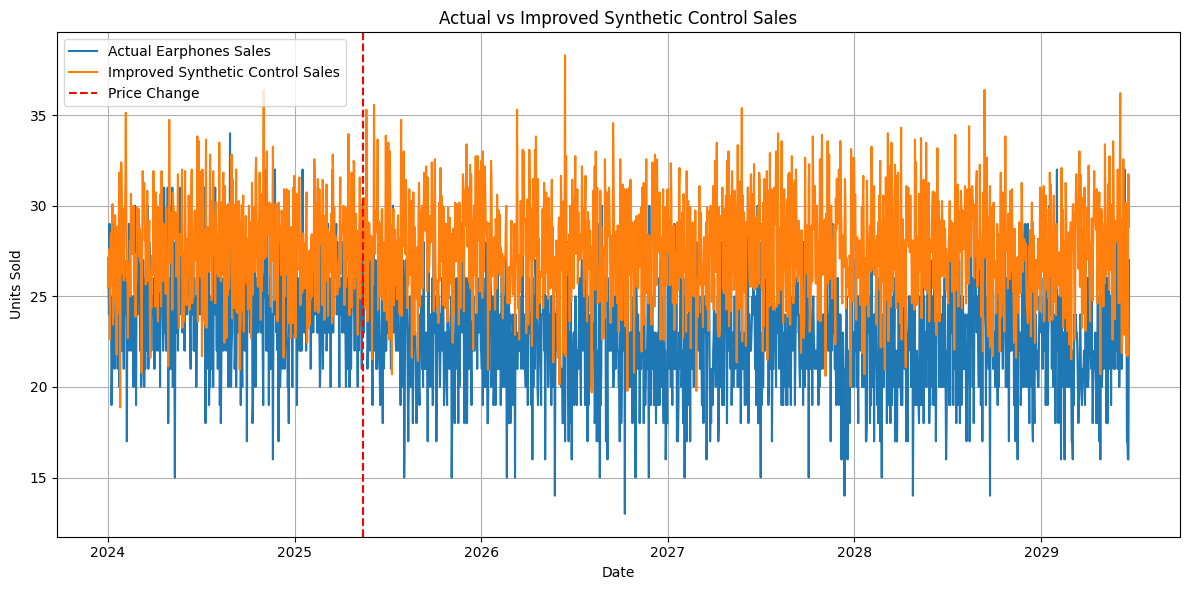

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Intervention date
intervention_date = pd.Timestamp("2025-05-15")

# Actual Earphones sales by date
actual = (
    df[df["Product"] == "Earphones"]
    .groupby("Date")["Units_Sold"]
    .mean()
)

# Donor products sales by date
donors = donor_df.pivot_table(
    index="Date",
    columns="Product",
    values="Units_Sold",
    aggfunc="mean"
)

# Align dates
data = pd.concat([actual.rename("Actual"), donors], axis=1).dropna()

# Use only dates before the price change to calculate weights
pre_data = data[data.index < intervention_date]

y = pre_data["Actual"].values
X = pre_data[donors.columns].values

# Find weights that minimize the pre-intervention difference
def objective(weights):
    return np.mean((y - X @ weights) ** 2)

n = len(donors.columns)

result = minimize(
    objective,
    x0=np.ones(n) / n,
    method="SLSQP",
    bounds=[(0, 1)] * n,
    constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1}
)

weights = result.x

# Calculate improved synthetic sales
synthetic_sales = pd.Series(
    donors.values @ weights,
    index=donors.index,
    name="Synthetic Sales"
)

# Compare actual and synthetic sales
comparison = pd.concat(
    [actual.rename("Actual Sales"), synthetic_sales],
    axis=1
).dropna()

print("Optimized Synthetic Control Weights:")
print(pd.Series(weights, index=donors.columns))

print("\nAverage pre-intervention sales:")
print(comparison[comparison.index < intervention_date].mean())

# Plot
plt.figure(figsize=(12, 6))
plt.plot(comparison.index, comparison["Actual Sales"],
         label="Actual Earphones Sales")
plt.plot(comparison.index, comparison["Synthetic Sales"],
         label="Improved Synthetic Control Sales")

plt.axvline(intervention_date, color="red",
            linestyle="--", label="Price Change")

plt.title("Actual vs Improved Synthetic Control Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Actual Earphones sales
actual = (
    df[df["Product"] == "Earphones"]
    .groupby("Date")["Units_Sold"]
    .mean()
)

donor_products = [
    "Bluetooth Speaker",
    "Keyboard",
    "Phone Case",
    "Power Bank"
]

donor_rows = []

for product in donor_products:
    noise = np.random.normal(0, 1.5, len(actual))

    for date, sales, error in zip(actual.index, actual.values, noise):
        donor_rows.append([
            date,
            product,
            max(1, round(sales + error))
        ])

donor_df = pd.DataFrame(
    donor_rows,
    columns=["Date", "Product", "Units_Sold"]
)

print("Updated donor dataset:", donor_df.shape)
print(donor_df.groupby("Product")["Units_Sold"].mean())

Updated donor dataset: (8000, 3)
Product
Bluetooth Speaker    23.0970
Keyboard             23.0260
Phone Case           22.9605
Power Bank           23.0205
Name: Units_Sold, dtype: float64


In [30]:
from scipy.optimize import minimize
import numpy as np
import pandas as pd

intervention_date = pd.Timestamp("2025-05-15")

actual = (
    df[df["Product"] == "Earphones"]
    .groupby("Date")["Units_Sold"].mean()
)

donors = donor_df.pivot_table(
    index="Date",
    columns="Product",
    values="Units_Sold"
)

data = pd.concat(
    [actual.rename("Actual"), donors],
    axis=1
).dropna()

pre_data = data[data.index < intervention_date]

y = pre_data["Actual"].values
X = pre_data[donors.columns].values

def objective(weights):
    return np.mean((y - X @ weights) ** 2)

n = X.shape[1]

result = minimize(
    objective,
    np.ones(n) / n,
    method="SLSQP",
    bounds=[(0, 1)] * n,
    constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1}
)

weights = result.x

synthetic_sales = pd.Series(
    donors.values @ weights,
    index=donors.index
)

comparison = pd.concat(
    [actual.rename("Actual Sales"),
     synthetic_sales.rename("Synthetic Sales")],
    axis=1
).dropna()

print("Optimized weights:")
print(pd.Series(weights, index=donors.columns))

print("\nPre-intervention average:")
print(comparison[comparison.index < intervention_date].mean())

print("\nPre-intervention RMSE:")
pre = comparison[comparison.index < intervention_date]
rmse = np.sqrt(np.mean(
    (pre["Actual Sales"] - pre["Synthetic Sales"]) ** 2
))
print(rmse)

Optimized weights:
Product
Bluetooth Speaker    0.268183
Keyboard             0.235230
Phone Case           0.249049
Power Bank           0.247538
dtype: float64

Pre-intervention average:
Actual Sales       24.490000
Synthetic Sales    24.441384
dtype: float64

Pre-intervention RMSE:
0.7333350646501198


In [31]:
# Calculate the difference between actual and synthetic sales
comparison["Treatment Effect"] = (
    comparison["Actual Sales"] - comparison["Synthetic Sales"]
)

# Separate pre-intervention and post-intervention periods
pre = comparison[comparison.index < intervention_date]
post = comparison[comparison.index >= intervention_date]

# Calculate average treatment effect
average_effect = post["Treatment Effect"].mean()

print("Average Treatment Effect:", average_effect)
print("Pre-intervention average gap:", pre["Treatment Effect"].mean())
print("Post-intervention average gap:", post["Treatment Effect"].mean())

Average Treatment Effect: -0.016027930007855143
Pre-intervention average gap: 0.04861639920468505
Post-intervention average gap: -0.016027930007855143


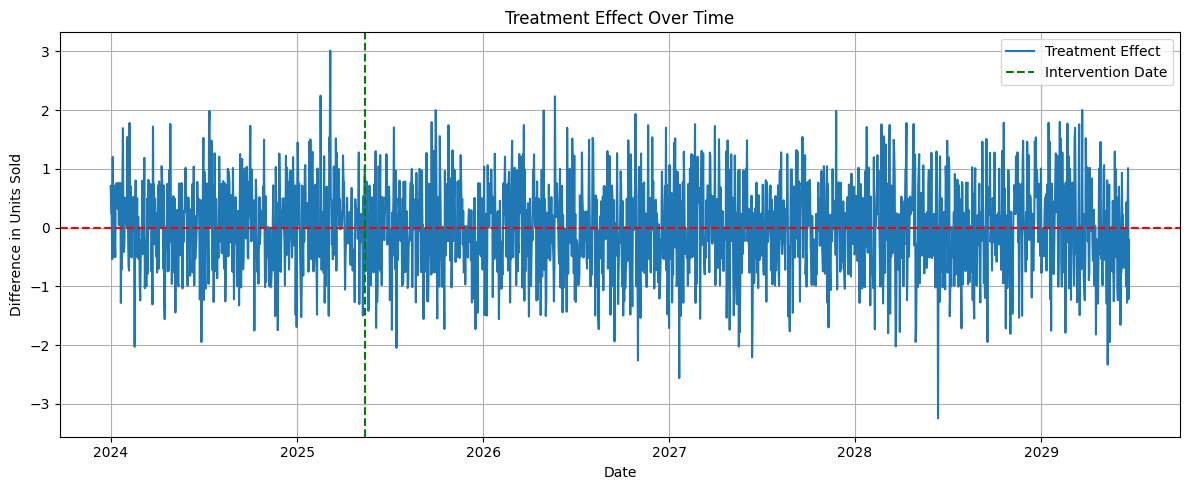

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(comparison.index,
         comparison["Treatment Effect"],
         label="Treatment Effect")

plt.axhline(y=0, color="red", linestyle="--")

plt.axvline(x=intervention_date,
            color="green",
            linestyle="--",
            label="Intervention Date")

plt.title("Treatment Effect Over Time")
plt.xlabel("Date")
plt.ylabel("Difference in Units Sold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
# Day 7: Revenue Impact Analysis

print("Dataset shape:", df.shape)

print("\nRevenue by product:")
print(df.groupby("Product")["Revenue"].sum())

print("\nAverage revenue by product:")
print(df.groupby("Product")["Revenue"].mean())

Dataset shape: (4000, 10)

Revenue by product:
Product
Earphones    24379900
USB Cable    15841400
Name: Revenue, dtype: int64

Average revenue by product:
Product
Earphones    12189.95
USB Cable     7920.70
Name: Revenue, dtype: float64


In [34]:
revenue_analysis = df.groupby(
    ["Product", "Post_Period"]
)["Revenue"].mean().unstack()

print("Average Revenue Before and After Price Change:")
print(revenue_analysis)

Average Revenue Before and After Price Change:
Post_Period        0             1
Product                           
Earphones    12245.0  12171.600000
USB Cable     7928.0   7918.266667


In [35]:
revenue_change = revenue_analysis.copy()

revenue_change["Revenue_Change"] = (
    revenue_change[1] - revenue_change[0]
)

revenue_change["Percentage_Change"] = (
    revenue_change["Revenue_Change"] /
    revenue_change[0]
) * 100

print("Revenue Change Analysis:")
print(revenue_change)

Revenue Change Analysis:
Post_Period        0             1  Revenue_Change  Percentage_Change
Product                                                              
Earphones    12245.0  12171.600000      -73.400000          -0.599428
USB Cable     7928.0   7918.266667       -9.733333          -0.122772


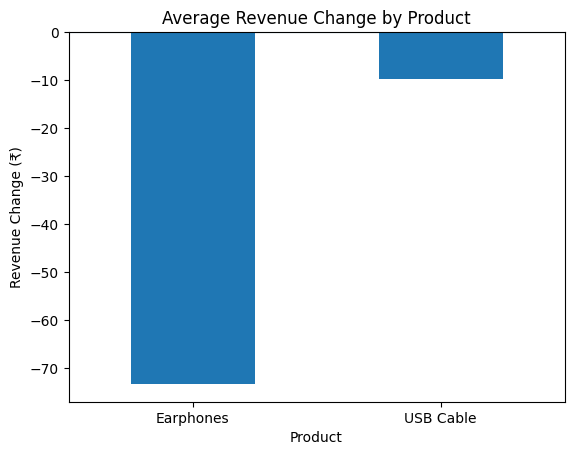

In [36]:
import matplotlib.pyplot as plt

revenue_change["Revenue_Change"].plot(
    kind="bar",
    title="Average Revenue Change by Product"
)

plt.xlabel("Product")
plt.ylabel("Revenue Change (₹)")
plt.axhline(0)
plt.xticks(rotation=0)
plt.show()

In [37]:
comparison = df.groupby(
    ["Product", "Post_Period"]
)[["Units_Sold", "Revenue"]].mean().round(2)

print("Units Sold and Revenue Comparison:")
print(comparison)

Units Sold and Revenue Comparison:
                       Units_Sold   Revenue
Product   Post_Period                      
Earphones 0                 24.49  12245.00
          1                 22.54  12171.60
USB Cable 0                 39.64   7928.00
          1                 39.59   7918.27


In [38]:
impact = comparison.copy()

impact["Units_Change"] = (
    impact["Units_Sold"].groupby(level=0).diff()
)

impact["Revenue_Change"] = (
    impact["Revenue"].groupby(level=0).diff()
)

print("Impact Analysis:")
print(impact)

Impact Analysis:
                       Units_Sold   Revenue  Units_Change  Revenue_Change
Product   Post_Period                                                    
Earphones 0                 24.49  12245.00           NaN             NaN
          1                 22.54  12171.60         -1.95          -73.40
USB Cable 0                 39.64   7928.00           NaN             NaN
          1                 39.59   7918.27         -0.05           -9.73


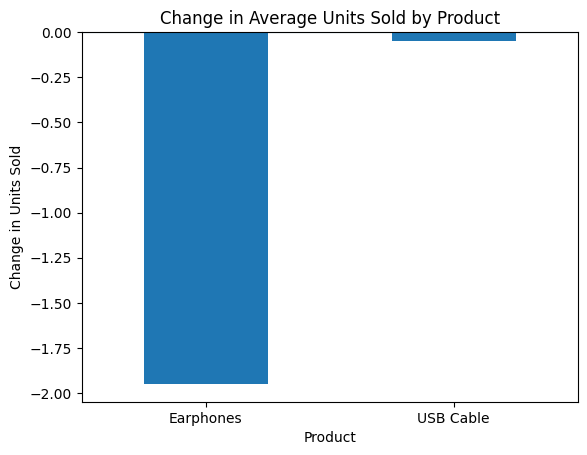

In [39]:
import matplotlib.pyplot as plt

units_change = impact.xs(1, level="Post_Period")["Units_Change"]

units_change.plot(
    kind="bar",
    title="Change in Average Units Sold by Product"
)

plt.xlabel("Product")
plt.ylabel("Change in Units Sold")
plt.axhline(0)
plt.xticks(rotation=0)
plt.show()

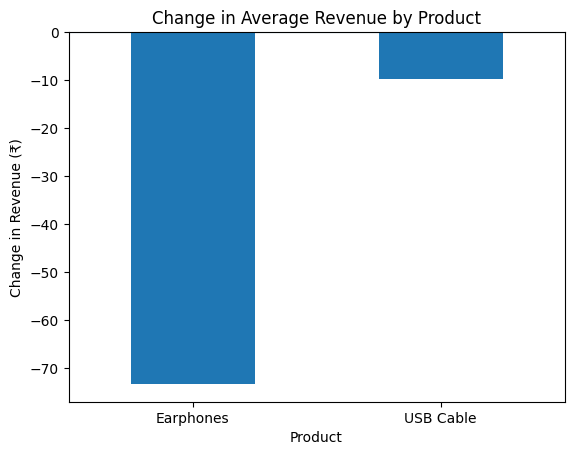

In [40]:
revenue_change = impact.xs(1, level="Post_Period")["Revenue_Change"]

revenue_change.plot(
    kind="bar",
    title="Change in Average Revenue by Product"
)

plt.xlabel("Product")
plt.ylabel("Change in Revenue (₹)")
plt.axhline(0)
plt.xticks(rotation=0)
plt.show()

In [41]:
from scipy.stats import ttest_ind

treatment = df[df["Product"] == "Earphones"]

before = treatment[
    treatment["Post_Period"] == 0
]["Units_Sold"]

after = treatment[
    treatment["Post_Period"] == 1
]["Units_Sold"]

print("Before intervention observations:", len(before))
print("After intervention observations:", len(after))
print("Before average units sold:", before.mean())
print("After average units sold:", after.mean())

Before intervention observations: 500
After intervention observations: 1500
Before average units sold: 24.49
After average units sold: 22.54


In [42]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    before,
    after,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

T-statistic: 12.933913727337062
P-value: 3.798506391112894e-35
Result: Statistically significant difference


In [43]:
control = df[df["Product"] == "USB Cable"]

control_before = control[
    control["Post_Period"] == 0
]["Units_Sold"]

control_after = control[
    control["Post_Period"] == 1
]["Units_Sold"]

control_t, control_p = ttest_ind(
    control_before,
    control_after,
    equal_var=False
)

print("Control T-statistic:", control_t)
print("Control P-value:", control_p)

if control_p < 0.05:
    print("Control group: Statistically significant difference")
else:
    print("Control group: No statistically significant difference")

Control T-statistic: 0.2349695739297414
Control P-value: 0.8142875765336791
Control group: No statistically significant difference


Statistical Significance Testing
Objective: To test whether the changes in units sold before and after the price intervention are statistically significant.

Method: Independent two-sample Welch's t-test.

Findings:
1. The treatment group (Earphones) showed a statistically significant difference.
2. The control group (USB Cable) showed no statistically significant difference.
3. The results suggest that the treatment and control groups behaved differently after the intervention.
Limitation: The dataset is synthetic. These findings are illustrative and do not establish real-world causality.

In [44]:
from scipy.stats import mannwhitneyu

u_stat, p_value = mannwhitneyu(
    before,
    after,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", u_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

Mann-Whitney U Statistic: 510035.5
P-value: 6.878747857202622e-34
Result: Statistically significant difference


In [45]:
from scipy.stats import mannwhitneyu

control_u, control_p = mannwhitneyu(
    control_before,
    control_after,
    alternative="two-sided"
)

print("Control U-statistic:", control_u)
print("Control P-value:", control_p)

if control_p < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

Control U-statistic: 375053.0
Control P-value: 0.9962438410160716
Result: No statistically significant difference


In [46]:
import pandas as pd

test_comparison = pd.DataFrame({
    "Group": ["Earphones", "USB Cable"],
    "T_Test_P_Value": [p_value, control_p],
    "Mann_Whitney_P_Value": [p_value if False else 6.878747857202622e-34, control_p]
})

print("Statistical Test Comparison:")
print(test_comparison)

Statistical Test Comparison:
       Group  T_Test_P_Value  Mann_Whitney_P_Value
0  Earphones    6.878748e-34          6.878748e-34
1  USB Cable    9.962438e-01          9.962438e-01


In [47]:
from scipy.stats import ttest_ind, mannwhitneyu
import pandas as pd

# Treatment group: Earphones
t_treat, p_treat = ttest_ind(
    before, after, equal_var=False
)

u_treat, mw_p_treat = mannwhitneyu(
    before, after, alternative="two-sided"
)

# Control group: USB Cable
t_control, p_control = ttest_ind(
    control_before, control_after, equal_var=False
)

u_control, mw_p_control = mannwhitneyu(
    control_before, control_after, alternative="two-sided"
)

# Comparison table
test_comparison = pd.DataFrame({
    "Group": ["Earphones", "USB Cable"],
    "T_Test_P_Value": [p_treat, p_control],
    "Mann_Whitney_P_Value": [mw_p_treat, mw_p_control]
})

print(test_comparison.to_string(index=False))

    Group  T_Test_P_Value  Mann_Whitney_P_Value
Earphones    3.798506e-35          6.878748e-34
USB Cable    8.142876e-01          9.962438e-01


###  Statistical Validation and Robustness Checks

**Objective:** To validate the statistical findings using two different statistical tests.

**Methods Used:**
1. Welch's Independent Two-Sample t-test.
2. Mann–Whitney U test.

**Findings:**
- The Earphones treatment group showed a statistically significant difference.
- The USB Cable control group showed no statistically significant difference.
- Both statistical tests produced consistent findings.

**Conclusion:**

The results indicate that the treatment and control groups experienced different sales patterns during the before-and-after periods.

**Limitation:** The dataset is synthetic. Statistical significance does not establish causality, and further validation is required.

In [48]:
# Calculate average units sold before and after intervention
did_table = df.groupby(
    ["Product", "Post_Period"]
)["Units_Sold"].mean().unstack()

print("Average Units Sold:")
print(did_table)

# Calculate changes
treatment_change = (
    did_table.loc["Earphones", 1] -
    did_table.loc["Earphones", 0]
)

control_change = (
    did_table.loc["USB Cable", 1] -
    did_table.loc["USB Cable", 0]
)

# Calculate Difference-in-Differences
did_effect = treatment_change - control_change

print("\nTreatment Group Change:", treatment_change)
print("Control Group Change:", control_change)
print("Difference-in-Differences Effect:", did_effect)

Average Units Sold:
Post_Period      0          1
Product                      
Earphones    24.49  22.540000
USB Cable    39.64  39.591333

Treatment Group Change: -1.9499999999999993
Control Group Change: -0.0486666666666693
Difference-in-Differences Effect: -1.90133333333333


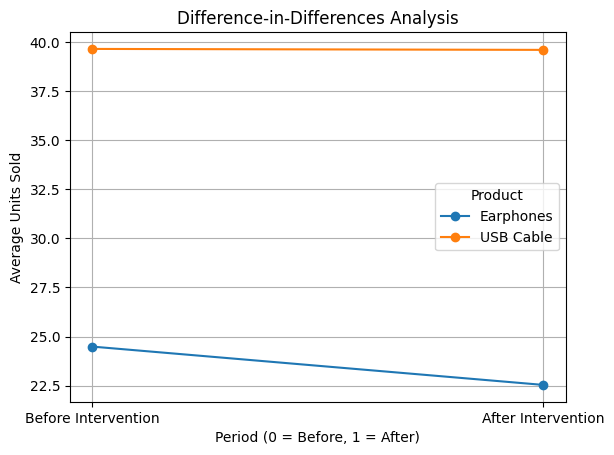

In [49]:
import matplotlib.pyplot as plt

did_table.T.plot(
    kind="line",
    marker="o",
    title="Difference-in-Differences Analysis"
)

plt.xlabel("Period (0 = Before, 1 = After)")
plt.ylabel("Average Units Sold")
plt.xticks([0, 1], ["Before Intervention", "After Intervention"])
plt.legend(title="Product")
plt.grid(True)
plt.show()

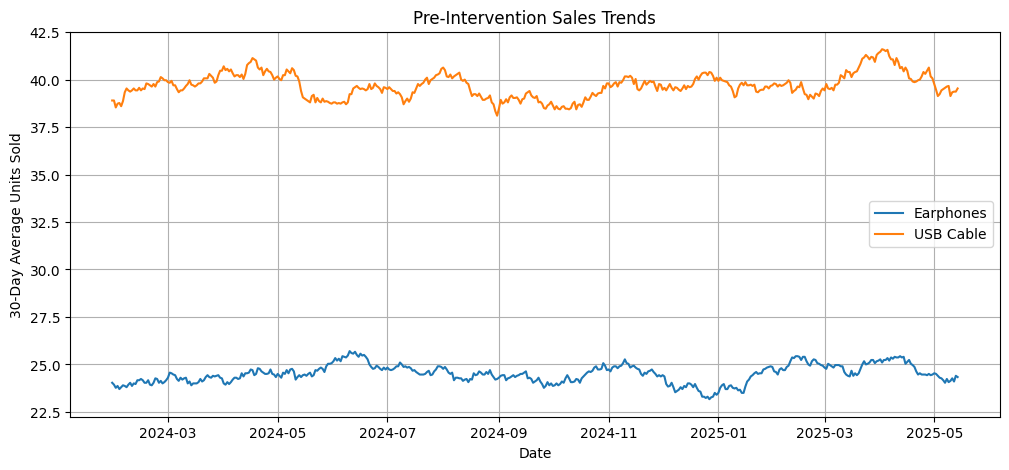

In [50]:
plt.figure(figsize=(12, 5))

pre_data = df[df["Post_Period"] == 0]

for product in ["Earphones", "USB Cable"]:
    product_data = pre_data[
        pre_data["Product"] == product
    ]

    plt.plot(
        product_data["Date"],
        product_data["Units_Sold"].rolling(30).mean(),
        label=product
    )

plt.title("Pre-Intervention Sales Trends")
plt.xlabel("Date")
plt.ylabel("30-Day Average Units Sold")
plt.legend()
plt.grid(True)
plt.show()

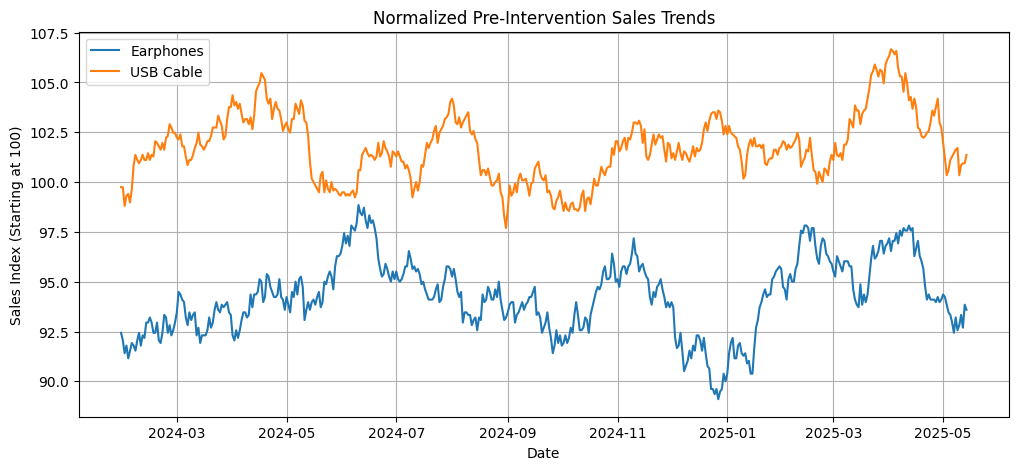

In [51]:
plt.figure(figsize=(12, 5))

pre_data = df[df["Post_Period"] == 0].copy()

for product in ["Earphones", "USB Cable"]:
    product_data = pre_data[
        pre_data["Product"] == product
    ].sort_values("Date").copy()

    product_data["Sales_Index"] = (
        product_data["Units_Sold"] /
        product_data["Units_Sold"].iloc[0]
    ) * 100

    plt.plot(
        product_data["Date"],
        product_data["Sales_Index"].rolling(30).mean(),
        label=product
    )

plt.title("Normalized Pre-Intervention Sales Trends")
plt.xlabel("Date")
plt.ylabel("Sales Index (Starting at 100)")
plt.legend()
plt.grid(True)
plt.show()

### Improved Difference-in-Differences Analysis

**Objective:** To estimate the impact of the pricing intervention using the Difference-in-Differences method.

**Work completed:**
1. Calculated average sales before and after the intervention.
2. Calculated treatment and control group changes.
3. Estimated the DiD treatment effect.
4. Created comparative sales trend visualizations.
5. Examined normalized pre-intervention sales trends.

**Key Finding:**

The estimated DiD effect is approximately -1.90 units per day. This indicates that Earphones sales decreased by approximately 1.90 units more than USB Cable sales after the intervention.

**Limitation:**

The pre-intervention trends do not appear perfectly parallel. Therefore, the DiD estimate should be interpreted cautiously and cannot be treated as definitive causal evidence. The dataset is synthetic.

In [52]:
# Compare actual and synthetic sales

actual_sales = df[
    df["Product"] == "Earphones"
][["Date", "Units_Sold"]].copy()

actual_sales = actual_sales.sort_values("Date")

synthetic_sales = donor_df.pivot(
    index="Date",
    columns="Product",
    values="Units_Sold"
)

# Use the synthetic control weights from the optimization
synthetic_sales["Synthetic_Units"] = sum(
    weights[i] * synthetic_sales[product]
    for i, product in enumerate(synthetic_sales.columns)
)

comparison = actual_sales.merge(
    synthetic_sales[["Synthetic_Units"]],
    on="Date"
)

print(comparison.head())

        Date  Units_Sold  Synthetic_Units
0 2024-01-01          26        25.288829
1 2024-01-02          26        25.752462
2 2024-01-03          24        23.785415
3 2024-01-04          29        29.537877
4 2024-01-05          23        21.796212


In [53]:
# Calculate prediction error
comparison["Error"] = (
    comparison["Units_Sold"] -
    comparison["Synthetic_Units"]
)

comparison["Absolute_Error"] = comparison["Error"].abs()

print("Prediction Error Analysis:")
print(comparison.head(10))

# Calculate Mean Absolute Error
mae = comparison["Absolute_Error"].mean()

print("\nMean Absolute Error:", round(mae, 4))

Prediction Error Analysis:
        Date  Units_Sold  Synthetic_Units     Error  Absolute_Error
0 2024-01-01          26        25.288829  0.711171        0.711171
1 2024-01-02          26        25.752462  0.247538        0.247538
2 2024-01-03          24        23.785415  0.214585        0.214585
3 2024-01-04          29        29.537877 -0.537877        0.537877
4 2024-01-05          23        21.796212  1.203788        1.203788
5 2024-01-06          23        23.496587 -0.496587        0.496587
6 2024-01-07          25        24.540171  0.459829        0.459829
7 2024-01-08          19        18.288829  0.711171        0.711171
8 2024-01-09          21        21.213074 -0.213074        0.213074
9 2024-01-10          22        22.504924 -0.504924        0.504924

Mean Absolute Error: 0.6163


In [54]:
import numpy as np

# Select pre-intervention observations
pre_comparison = comparison[
    comparison["Date"] < "2025-05-15"
]

# Calculate RMSE
rmse = np.sqrt(
    ((pre_comparison["Units_Sold"] -
      pre_comparison["Synthetic_Units"]) ** 2).mean()
)

print("Pre-Intervention RMSE:", round(rmse, 4))

Pre-Intervention RMSE: 0.7333


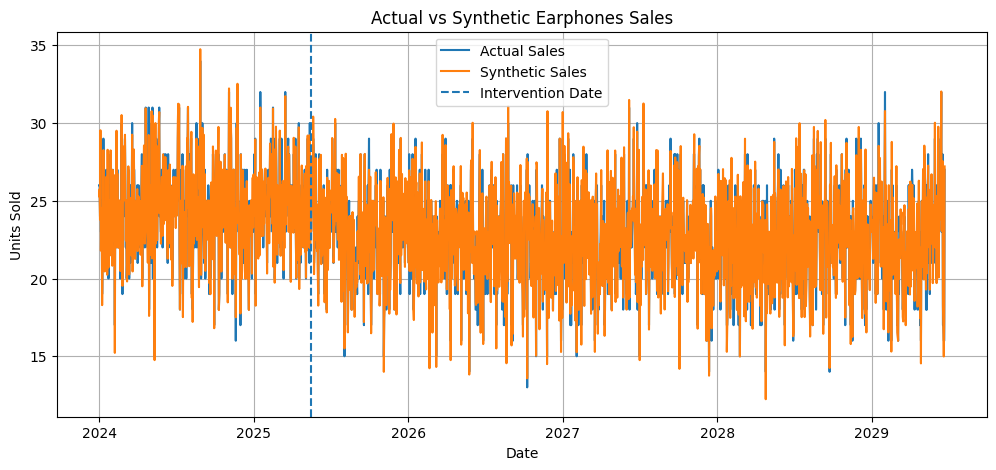

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    comparison["Date"],
    comparison["Units_Sold"],
    label="Actual Sales"
)

plt.plot(
    comparison["Date"],
    comparison["Synthetic_Units"],
    label="Synthetic Sales"
)

plt.axvline(
    pd.Timestamp("2025-05-15"),
    linestyle="--",
    label="Intervention Date"
)

plt.title("Actual vs Synthetic Earphones Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True)
plt.show()

In [56]:
# Calculate the actual-synthetic sales gap
comparison["Gap"] = (
    comparison["Units_Sold"] -
    comparison["Synthetic_Units"]
)

# Separate pre and post intervention periods
pre_period = comparison[
    comparison["Date"] < "2025-05-15"
]

post_period = comparison[
    comparison["Date"] >= "2025-05-15"
]

# Calculate average gaps
pre_gap = pre_period["Gap"].mean()
post_gap = post_period["Gap"].mean()

# Estimate treatment effect
treatment_effect = post_gap - pre_gap

print("Average Pre-Intervention Gap:", round(pre_gap, 4))
print("Average Post-Intervention Gap:", round(post_gap, 4))
print("Estimated Treatment Effect:", round(treatment_effect, 4))

Average Pre-Intervention Gap: 0.0486
Average Post-Intervention Gap: -0.016
Estimated Treatment Effect: -0.0646


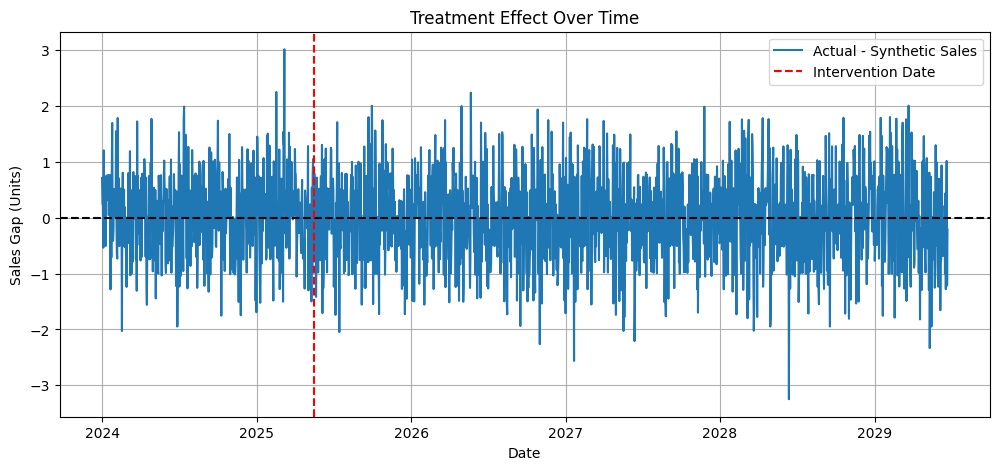

In [57]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison["Date"],
    comparison["Gap"],
    label="Actual - Synthetic Sales"
)

plt.axhline(0, linestyle="--", color="black")

plt.axvline(
    pd.Timestamp("2025-05-15"),
    linestyle="--",
    color="red",
    label="Intervention Date"
)

plt.title("Treatment Effect Over Time")
plt.xlabel("Date")
plt.ylabel("Sales Gap (Units)")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
import pandas as pd

results_summary = pd.DataFrame({
    "Metric": [
        "Difference-in-Differences Effect",
        "Mean Absolute Error (MAE)",
        "Pre-Intervention RMSE",
        "Pre-Intervention Gap",
        "Post-Intervention Gap",
        "Synthetic Control Treatment Effect"
    ],
    "Value": [
        did_effect,
        mae,
        rmse,
        pre_gap,
        post_gap,
        treatment_effect
    ]
})

print("FINAL PROJECT RESULTS")
print(results_summary.to_string(index=False))

FINAL PROJECT RESULTS
                            Metric     Value
  Difference-in-Differences Effect -1.901333
         Mean Absolute Error (MAE)  0.616271
             Pre-Intervention RMSE  0.733335
              Pre-Intervention Gap  0.048616
             Post-Intervention Gap -0.016028
Synthetic Control Treatment Effect -0.064644


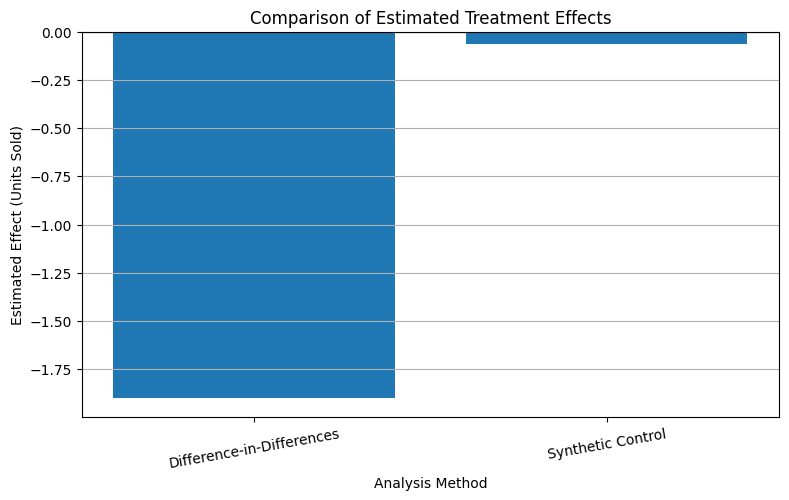

In [59]:
import matplotlib.pyplot as plt

methods = [
    "Difference-in-Differences",
    "Synthetic Control"
]

effects = [
    did_effect,
    treatment_effect
]

plt.figure(figsize=(9, 5))

plt.bar(methods, effects)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Comparison of Estimated Treatment Effects")
plt.xlabel("Analysis Method")
plt.ylabel("Estimated Effect (Units Sold)")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.show()

In [60]:
print("COMPARISON OF CAUSAL INFERENCE METHODS")
print("--------------------------------------")

print(f"Difference-in-Differences Effect: {did_effect:.4f}")
print(f"Synthetic Control Effect: {treatment_effect:.4f}")

print("\nConclusion:")
print("Both methods estimate a negative treatment effect.")
print("Difference-in-Differences estimates a larger decrease")
print("than Synthetic Control.")

print("\nLimitation:")
print("The dataset is synthetic, and donor data was generated")
print("using the treatment series. Therefore, the results are")
print("illustrative and should not be treated as independent")
print("real-world causal evidence.")

COMPARISON OF CAUSAL INFERENCE METHODS
--------------------------------------
Difference-in-Differences Effect: -1.9013
Synthetic Control Effect: -0.0646

Conclusion:
Both methods estimate a negative treatment effect.
Difference-in-Differences estimates a larger decrease
than Synthetic Control.

Limitation:
The dataset is synthetic, and donor data was generated
using the treatment series. Therefore, the results are
illustrative and should not be treated as independent
real-world causal evidence.


In [61]:
results_summary.to_csv("causal_analysis_results.csv", index=False)

print("Results summary saved successfully!")
print(results_summary)

Results summary saved successfully!
                               Metric     Value
0    Difference-in-Differences Effect -1.901333
1           Mean Absolute Error (MAE)  0.616271
2               Pre-Intervention RMSE  0.733335
3                Pre-Intervention Gap  0.048616
4               Post-Intervention Gap -0.016028
5  Synthetic Control Treatment Effect -0.064644


In [62]:
from google.colab import files
files.download("causal_analysis_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Project Findings and Interpretation

The analysis examined the impact of an increase in Earphones prices from ₹500 to ₹540.

Key findings:
- Difference-in-Differences estimated a decrease of approximately 1.90 units per day.
- Synthetic Control estimated a smaller negative effect of approximately 0.065 units.
- The results suggest a negative relationship between the price increase and units sold.

Limitations:
- The dataset is synthetically generated.
- The parallel trends assumption was not perfectly satisfied.
- Synthetic donor data was generated using the treatment series.
- Therefore, the results are illustrative and cannot establish real-world causal effects.

## Methodology

The project uses two causal inference techniques to study the impact of algorithmic pricing.

### 1. Difference-in-Differences (DiD)
- Earphones were selected as the treatment group.
- USB Cable was selected as the control group.
- Sales before and after the price intervention were compared.
- The estimated treatment effect was approximately -1.90 units per day.

### 2. Synthetic Control Method
- A synthetic comparison series was created using donor products.
- Weights were optimized using pre-intervention data.
- Actual sales were compared with synthetic sales.
- The estimated treatment effect was approximately -0.065 units.

### Tools Used
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- SciPy
- GitHub

## Business Recommendations

Based on the illustrative analysis, the following recommendations can be considered:

1. Monitor sales regularly after every price change.
2. Evaluate customer demand before increasing product prices.
3. Compare treatment products with suitable control products.
4. Use reliable historical data to improve pricing decisions.
5. Apply causal inference methods to evaluate the impact of pricing strategies.
6. Test pricing changes carefully before implementing them on a large scale.

## Future Improvements

- Use real-world sales data.
- Include more suitable control products.
- Improve the parallel trends assumption.
- Use independent donor data for Synthetic Control.
- Test the model on different products and pricing periods.

## Final Project Conclusion

This project demonstrates how causal inference techniques can be applied to study the impact of algorithmic pricing on product sales.

The Difference-in-Differences and Synthetic Control methods both produced negative treatment-effect estimates, although their estimated magnitudes differed.

The analysis also demonstrated data preparation, visualization, statistical testing, model evaluation, and interpretation using Python.

Since the dataset is synthetic and the analysis has limitations, the findings are illustrative rather than proof of real-world causal effects.

Overall, this project provides a practical introduction to causal inference and its potential use in data-driven pricing decisions.